# Лекция 3. Основные компоненты машинного обучения
В этой лекции мы подробнее рассмотрим основные компоненты нейронных сетей, с которыми познакомились ранее: слоями, сетями, целевыми функциями и оптимизаторами.
Исследуем три вводных примера использования нейронных сетей для решения практических задач:
1. классификацию отзывов о фильмах на положительные и отрицательные (бинарная классификация);
2. классификацию новостных лент по темам (многоклассовая классификация); 
3. оценку стоимости дома с учетом данных о недвижимости (регрессия).

#**Предсказание цен на дома: пример регрессии**

В двух предыдущих примерах мы познакомились с задачами классификации, цель которых состояла в предсказании одной дискретной метки для образца входных данных. Другим распространенным типом задач машинного обучения является регрессия, которая заключается в предсказании не дискретной метки, а значения на непрерывной числовой прямой: например, предсказание температуры воздуха на завтра по имеющимся метеорологическим данным или предсказание времени завершения программного проекта по его спецификациям.

**ПРИМЕЧАНИЕ**

Не путайте регрессию с алгоритмом логистической регрессии. Как ни странно, логистическая регрессия не является регрессионным алгоритмом — это алгоритм классификации.


##Набор данных с ценами на жилье в Бостоне
Мы попытаемся предсказать медианную цену на дома в пригороде Бостона в середине 1970-х по таким данным о пригороде того времени, как уровень преступности, ставка местного имущественного налога и т. д. Набор данных, который нам предстоит использовать, имеет интересное отличие от двух предыдущих примеров. Он содержит относительно немного образцов данных: всего 506, разбитых на 404 обучающих и 102 контрольных образца. И каждый признак во входных данных (например, уровень преступности) имеет свой масштаб. Например, некоторые признаки являются пропорциями и имеют значения между 0 и 1, другие — между 1 и 12 и т. д.

In [ ]:
from keras.datasets import boston_housing
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

57026/57026 [==============================] - 0s 0us/step


Посмотрим на данные:

In [ ]:
train_data.shape

(404, 13)

In [ ]:
test_data.shape

(102, 13)

Как видите, у нас имеются 404 обучающих и 102 контрольных образца, каждый с 13 числовыми признаками, такими как уровень преступности, среднее число комнат в доме, удаленность от центральных дорог и т. д.

Цели — медианные значения цен на дома, занимаемые собственниками, в тысячах долларов:

In [ ]:
train_targets

array([15.2, 42.3, 50. , 21.1, 17.7, 18.5, 11.3, 15.6, 15.6, 14.4, 12.1,
       17.9, 23.1, 19.9, 15.7,  8.8, 50. , 22.5, 24.1, 27.5, 10.9, 30.8,
       32.9, 24. , 18.5, 13.3, 22.9, 34.7, 16.6, 17.5, 22.3, 16.1, 14.9,
       23.1, 34.9, 25. , 13.9, 13.1, 20.4, 20. , 15.2, 24.7, 22.2, 16.7,
       12.7, 15.6, 18.4, 21. , 30.1, 15.1, 18.7,  9.6, 31.5, 24.8, 19.1,
       22. , 14.5, 11. , 32. , 29.4, 20.3, 24.4, 14.6, 19.5, 14.1, 14.3,
       15.6, 10.5,  6.3, 19.3, 19.3, 13.4, 36.4, 17.8, 13.5, 16.5,  8.3,
       14.3, 16. , 13.4, 28.6, 43.5, 20.2, 22. , 23. , 20.7, 12.5, 48.5,
       14.6, 13.4, 23.7, 50. , 21.7, 39.8, 38.7, 22.2, 34.9, 22.5, 31.1,
       28.7, 46. , 41.7, 21. , 26.6, 15. , 24.4, 13.3, 21.2, 11.7, 21.7,
       19.4, 50. , 22.8, 19.7, 24.7, 36.2, 14.2, 18.9, 18.3, 20.6, 24.6,
       18.2,  8.7, 44. , 10.4, 13.2, 21.2, 37. , 30.7, 22.9, 20. , 19.3,
       31.7, 32. , 23.1, 18.8, 10.9, 50. , 19.6,  5. , 14.4, 19.8, 13.8,
       19.6, 23.9, 24.5, 25. , 19.9, 17.2, 24.6, 13

Цены в основной массе находятся в диапазоне от 10 000 до 50 000 долларов США.

Данные выглядят следующим образом:

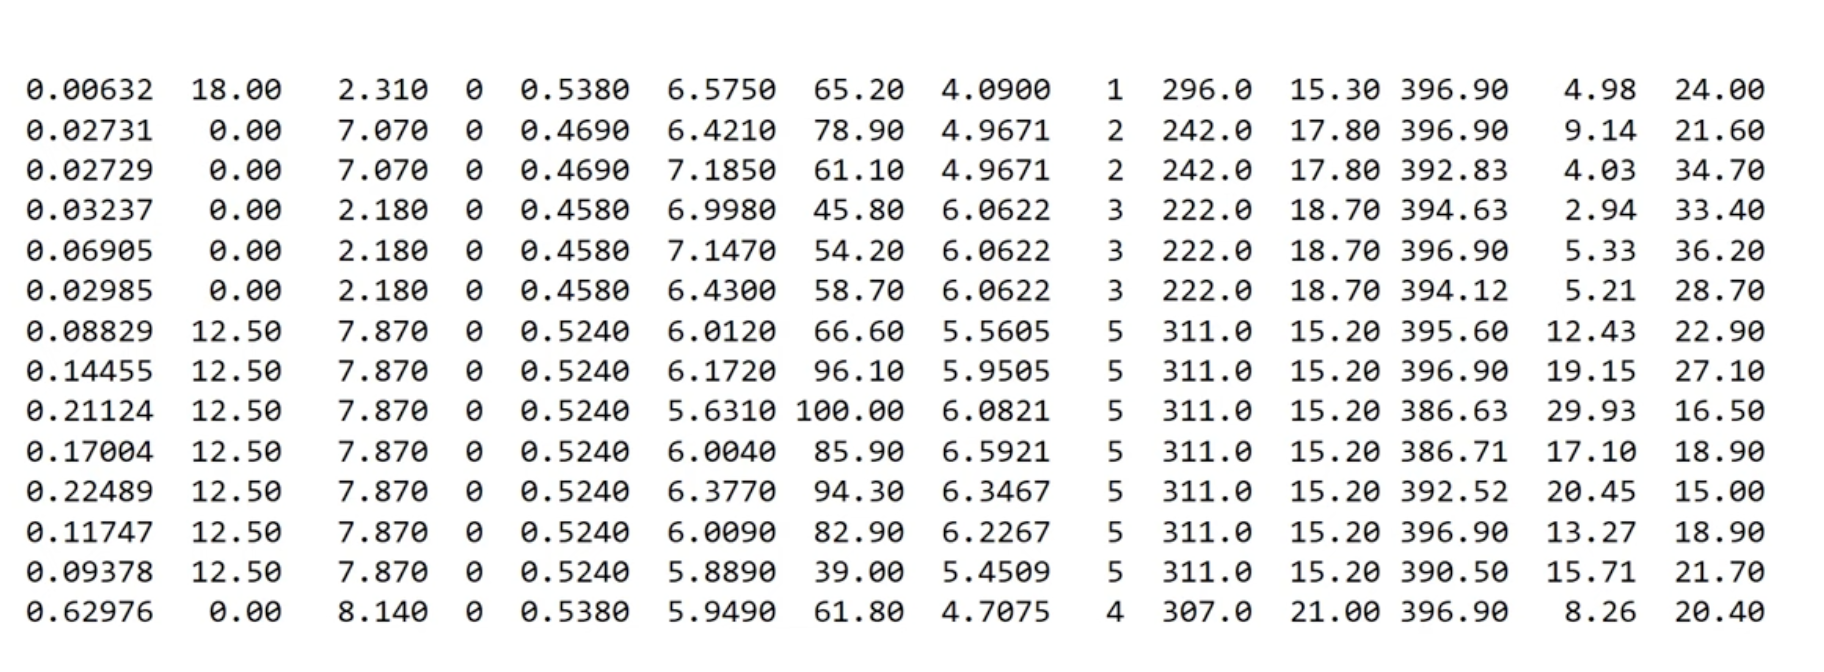

##Подготовка данных
Было бы проблематично передать в нейронную сеть значения, имеющие самые разные диапазоны. Сеть, конечно, сможет автоматически адаптироваться к таким разнородным данным, однако это усложнит обучение. На практике к таким данным принято применять нормализацию: для каждого признака во входных данных (столбца в матрице входных данных) из каждого значения вычитается среднее по этому признаку, и разность делится на стандартное отклонение, в результате признак центрируется по нулевому значению и имеет стандартное отклонение, равное единице. Такую нормализацию легко выполнить с помощью Numpy.

In [ ]:
mean = train_data.mean(axis=0) #среднее значение по всем столбцам
train_data -= mean
std = train_data.std(axis=0)
train_data /= std
test_data -= mean
test_data /= std

Обратите внимание на то, что величины, используемые для нормализации контрольных данных, вычисляются с использованием обучающих данных. Никогда не следует использовать в работе какие-либо значения, вычисленные по контрольным данным, даже для таких простых шагов, как нормализация данных.


##Конструирование сети
Из-за небольшого количества образцов мы будем использовать очень маленькую сеть с двумя слоями. Вообще говоря, чем меньше обучающих данных, тем скорее наступит переобучение, а использование маленькой сети — один из способов борьбы с ним.

In [ ]:
from keras import models
from keras import layers
def build_model():
  model = models.Sequential()
  model.add(layers.Dense(64, activation='relu', input_shape=(train_data.shape[1],)))
  model.add(layers.Dense(64, activation='relu'))
  model.add(layers.Dense(1))
  model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])
  return model

Сеть заканчивается одномерным слоем, не имеющим функции активации (это линейный слой). Это типичная конфигурация для скалярной регрессии (целью которой является предсказание одного значения на непрерывной числовой прямой). Применение функции активации могло бы ограничить диапазон выходных значений: например, если в последнем слое применить функцию активации sigmoid, сеть обучилась бы предсказывать только значения из диапазона между 0 и 1. В данном случае, с линейным последним слоем, сеть способна предсказывать значения из любого диапазона.

Обратите внимание на то, что сеть компилируется с функцией потерь mse — mean squared error (среднеквадратичная ошибка), вычисляющей квадрат разности между предсказанными и целевыми значениями. Эта функция широко используется в задачах регрессии.

Мы также включили новый параметр в мониторинг на этапе обучения: mae — mean absolute error (средняя абсолютная ошибка). Это абсолютное значение разности между предсказанными и целевыми значениями. Например, значение MAE, равное 0,5, в этой задаче означает, что в среднем прогнозы отклоняются на 500 долларов США.

##Оценка решения методом перекрестной проверки по K блокам
Чтобы оценить качество сети в ходе корректировки ее параметров (таких, как количество эпох обучения), можно разбить исходные данные на обучающий и проверочный наборы, как это делалось в предыдущих примерах. Однако так как у нас и без того небольшой набор данных, проверочный набор получился бы слишком маленьким (скажем, что-нибудь около 100 образцов). Как следствие, оценки при проверке могут сильно меняться в зависимости от того, какие данные попадут в проверочный и обучающий наборы: оценки при проверке могут иметь слишком большой разброс. Это не позволит надежно оценить качество модели.

Лучшей практикой в таких ситуациях является применение перекрестной проверки по K блокам (K-fold cross-validation), как показано на рисунке ниже. Суть ее заключается в разделении доступных данных на K блоков (обычно K = 4 или 5), создании K идентичных моделей и обучении каждой на K—1 блоках с оценкой по оставшимся блокам. По полученным K оценкам вычисляется среднее значение, которое принимается как оценка модели. В коде такая проверка реализуется достаточно просто.

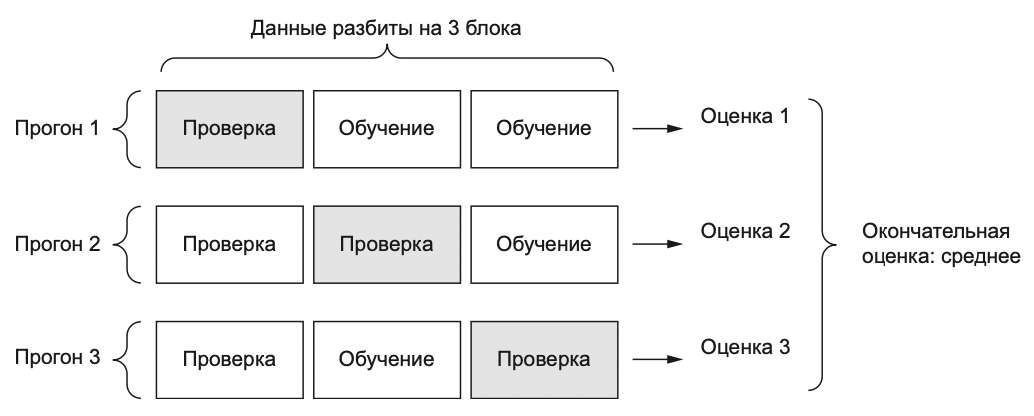

In [ ]:
import numpy as np
k = 4
num_val_samples = len(train_data) // k
num_epochs = 100
all_scores = []
for i in range(k):
    print('processing fold #', i)
    #Подготовка проверочных данных: данных из блока с номером k
    val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples] #[0:101]
    val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]
    #Подготовка обучающих данных: данных из остальных блоков
    #concatenate - соединяет данные в массив
    partial_train_data = np.concatenate([train_data[:i * num_val_samples], train_data[(i + 1) * num_val_samples:]], axis=0) #[101:404]
    partial_train_targets = np.concatenate([train_targets[:i * num_val_samples], train_targets[(i + 1) * num_val_samples:]], axis=0)
    model = build_model() #Конструирование модели Keras (уже скомпилированной)
    #Обучение модели (в режиме без вывода сообщений, verbose = 0)
    model.fit(partial_train_data, partial_train_targets, epochs=num_epochs, batch_size=1, verbose=1)
    #Оценка модели по проверочным данным
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=1)
    all_scores.append(val_mae)

processing fold # 0
Epoch 1/100
303/303 [==============================] - 1s 2ms/step - loss: 234.0905 - mae: 11.5058
Epoch 2/100
303/303 [==============================] - 1s 2ms/step - loss: 31.0225 - mae: 3.7040
Epoch 3/100
303/303 [==============================] - 1s 2ms/step - loss: 22.6692 - mae: 3.0955
Epoch 4/100
303/303 [==============================] - 1s 2ms/step - loss: 19.2209 - mae: 2.8189
Epoch 5/100
303/303 [==============================] - 1s 2ms/step - loss: 17.6502 - mae: 2.6957
Epoch 6/100
303/303 [==============================] - 1s 2ms/step - loss: 15.7799 - mae: 2.5780
Epoch 7/100
303/303 [==============================] - 0s 2ms/step - loss: 15.5484 - mae: 2.4858
Epoch 8/100
303/303 [==============================] - 1s 2ms/step - loss: 14.0027 - mae: 2.4575
Epoch 9/100
303/303 [==============================] - 1s 2ms/step - loss: 13.4787 - mae: 2.3375
Epoch 10/100
303/303 [==============================] - 1s 2ms/step - loss: 12.4298 - mae: 2.3169
Epoch 1

In [ ]:
all_scores

[2.1426093578338623, 2.865093946456909, 2.495785713195801, 2.549046516418457]

In [ ]:
np.mean(all_scores)

2.5131338834762573

Разные прогоны действительно показывают разные оценки, от 2,1 до 2.6. Средняя (2,5) выглядит более достоверно, чем любая из оценок отдельных прогонов, — в этом главная ценность перекрестной проверки по K блокам. В данном случае средняя ошибка составила 2513 долларов, что довольно много, если вспомнить, что цены колеблются в диапазоне от 10 000 до 50 000 долларов.
Попробуем увеличить время обучения сети до 500 эпох. Чтобы получить информацию о качестве обучения модели в каждую эпоху, изменим цикл обучения и добавим сохранение оценки проверки перед началом эпохи.

In [ ]:
num_epochs = 500
all_mae_histories = []
for i in range(k):
  print('processing fold #', i)
  #Подготовка проверочных данных: данных из блока с номером k
  val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
  val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]
  #Подготовка обучающих данных: данных из остальных блоков
  partial_train_data = np.concatenate([train_data[:i * num_val_samples],
                                       train_data[(i + 1) * num_val_samples:]],
                                      axis=0)
  partial_train_targets = np.concatenate([train_targets[:i * num_val_samples],
                                          train_targets[(i + 1) * num_val_samples:]],
                                         axis=0)

  #Конструирование модели Keras (уже скомпилированной)
  model = build_model()
  #Обучение модели (в режиме без вывода сообщений, verbose = 0)
  history = model.fit(partial_train_data, partial_train_targets,
                      validation_data=(val_data, val_targets),
                      epochs=num_epochs, batch_size=1, verbose=0)
  mae_history = history.history['val_mae']
  all_mae_histories.append(mae_history)

processing fold # 0
processing fold # 1
processing fold # 2
processing fold # 3


Теперь можно вычислить средние значения метрики mae для всех прогонов.

In [ ]:
average_mae_history = [np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)]

Построим график

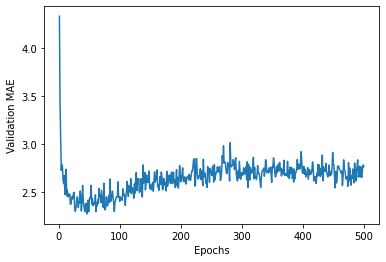

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(1, len(average_mae_history) + 1), average_mae_history)
plt.xlabel('Epochs')
plt.ylabel('Validation MAE')
plt.show()

Из-за проблем с масштабированием, а также ввиду относительно высокой дисперсии может быть немного затруднительно увидеть общую тенденцию. Давайте сделаем следующее:
* опустим первые 10 замеров, которые имеют другой масштаб, отличный от масштаба остальной кривой;
* заменим каждую оценку экспоненциальным скользящим средним по предыдущим оценкам, чтобы получить более гладкую кривую.
Результат показан на рисунке ниже.
Согласно этому графику, наилучшая оценка MAE достигается после 80 эпох. После этого момента начинается переобучение.

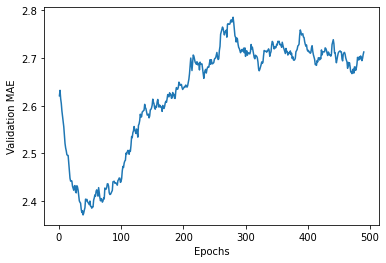

In [ ]:
def smooth_curve(points, factor=0.9):
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points
smooth_mae_history = smooth_curve(average_mae_history[10:])
plt.plot(range(1, len(smooth_mae_history) + 1), smooth_mae_history)
plt.xlabel('Epochs')
plt.ylabel('Validation MAE')
plt.show()

По окончании настройки других параметров модели (кроме количества эпох можно также скорректировать количество промежуточных слоев) можно обучить окончательную версию модели на всех обучающих данных, а затем оценить ее качество на контрольных данных.


In [ ]:
#Получить новую скомпилированную модель
model = build_model()
#Обучить ее на всем объеме обучающих данных
model.fit(train_data, train_targets, epochs=80, batch_size=16, verbose=0)
test_mse_score, test_mae_score = model.evaluate(test_data, test_targets)

4/4 [==============================] - 0s 3ms/step - loss: 14.7182 - mae: 2.5160


Вот окончательный результат:

In [ ]:
print("Средняя абсолютная ошибка (тысяч долларов):", test_mae_score)

Средняя абсолютная ошибка (тысяч долларов): 2.5159616470336914


Средняя ошибка все еще составляет около 2515 долларов.

Использование сети для предсказания цен недвижимости:

In [ ]:
pred = model.predict(test_data)

4/4 [==============================] - 0s 3ms/step


In [ ]:
print("Предсказанная стоимость:", pred[1][0], ", правильная стоимость:", test_targets[1])

Предсказанная стоимость: 18.296022 , правильная стоимость: 18.8


In [ ]:
print("Предсказанная стоимость:", pred[50][0], ", правильная стоимость:", test_targets[50])

Предсказанная стоимость: 34.937458 , правильная стоимость: 35.4


In [ ]:
print("Предсказанная стоимость:", pred[100][0], ", правильная стоимость:", test_targets[100])

Предсказанная стоимость: 29.887486 , правильная стоимость: 26.7


##Вот какие выводы вы должны сделать из этого примера:
* Регрессия выполняется с применением иных функций потерь, нежели классификация. Для регрессии часто используется функция потерь, вычисляющая среднеквадратичную ошибку (Mean Squared Error, MSE).
* Аналогично, для регрессии используются иные метрики оценки, нежели при классификации; понятие точности неприменимо для регрессии, поэтому для оценки качества часто применяется средняя абсолютная ошибка (Mean Absolute Error, MAE).
* Когда признаки образцов на входе имеют значения из разных диапазонов, их необходимо предварительно масштабировать.
* При небольшом объеме входных данных надежно оценить качество модели поможет метод перекрестной проверки по K блокам.
* При небольшом объеме обучающих данных предпочтительнее использовать маленькие сети с небольшим количеством промежуточных слоев (обычно с одним или двумя), чтобы избежать серьезного переобучения.

#Задание 3
Выполнить реализацию примера на данных недвижимости по городу Якутску.

# Итоги лекции

* Исходные данные обычно приходится подвергать предварительной обработке перед передачей в нейронную сеть.
* Когда данные включают в себя признаки со значениями из разных диапазонов, их необходимо предварительно масштабировать.
* В процессе обучения нейронных сетей в некоторый момент наступает эффект переобучения, из-за чего падает качество результатов оценки сети на данных, которые она прежде не видела.
* При небольшом объеме входных данных используйте небольшие сети с одним или двумя промежуточными слоями, чтобы избежать серьезного переобучения.
* В том случае, когда данные делятся на большое число категорий, у вас может возникнуть узкое место для информации, если вы слишком сильно ограничите размерность промежуточных слоев.
* При регрессии применяются иные функции потерь и метрики, нежели при классификации.
* При небольшом объеме входных данных надежно оценить качество модели поможет метод перекрестной проверки по K блокам.